# MediScan-AI Diabetes Prediction Model

## 1. Import Libraries

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    cross_val_score
)

from sklearn.preprocessing import StandardScaler

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

import joblib

## 2. Load Dataset

In [4]:
import pandas as pd #Imports the Pandas library (shortened as pd) to work with datasets and tables.

diabetes_df = pd.read_csv("../data/raw/diabetes.csv")   #Reads the diabetes.csv file and stores it as a DataFrame named diabetes_df.

diabetes_df.head()     #Displays the first 5 rows of the dataset to quickly verify that the data has been loaded correctly.

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
diabetes_df.shape  #Returns the number of rows and columns in the dataset as a tuple (rows, columns).

(768, 9)

In [6]:
diabetes_df.info()   #Displays a summary of the dataset, including column names, data types, non-null values, and memory usage.

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## 3. Explore Dataset

In [7]:
diabetes_df.head()      #Displays the first 5 rows of the dataset for a quick preview of the data.

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [8]:
diabetes_df.tail()      #Displays the last 5 rows of the dataset for a quick preview of the ending records.

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [9]:
diabetes_df.describe().T         #Generates summary statistics (count, mean, standard deviation, minimum, maximum, and quartiles) for all numerical columns, displayed in a transposed format.

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [10]:
diabetes_df.isnull().sum()          #Returns the total number of missing (null) values in each column of the dataset.

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [11]:
diabetes_df.duplicated().sum()         #Returns the total number of duplicate rows present in the dataset.

np.int64(0)

In [12]:
diabetes_df["Outcome"].value_counts()           #Returns the count of each unique value in the Outcome column (e.g., diabetic and non-diabetic cases).

Outcome
0    500
1    268
Name: count, dtype: int64

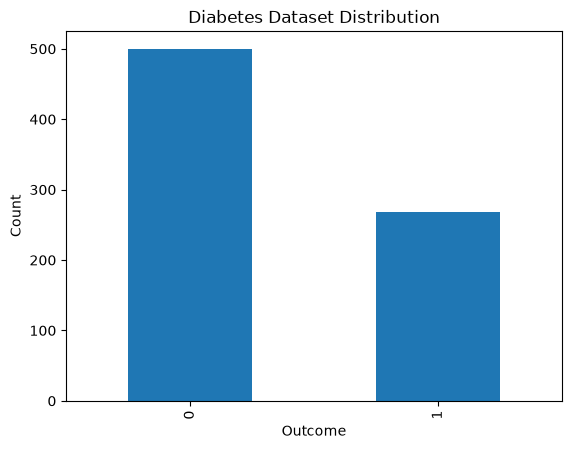

In [13]:
import matplotlib.pyplot as plt                        # Imports Matplotlib (pyplot) to create visualizations.Creates a bar chart showing the number of diabetic (1) and non-diabetic (0) patients, with labeled axes and a title.  plt.show() displays the graph.

diabetes_df["Outcome"].value_counts().plot(
    kind="bar",
    xlabel="Outcome",
    ylabel="Count",
    title="Diabetes Dataset Distribution"
)

plt.show()

## 4. Data Cleaning

In [14]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in cols:
    print(f"{col}: {(diabetes_df[col] == 0).sum()} zero values")

Glucose: 5 zero values
BloodPressure: 35 zero values
SkinThickness: 227 zero values
Insulin: 374 zero values
BMI: 11 zero values


In [15]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

for col in cols:
    diabetes_df[col] = diabetes_df[col].replace(0, diabetes_df[col].median())

In [16]:
for col in cols:
    print(f"{col}: {(diabetes_df[col] == 0).sum()} zero values")

Glucose: 0 zero values
BloodPressure: 0 zero values
SkinThickness: 0 zero values
Insulin: 0 zero values
BMI: 0 zero values


## 5. Exploratory Data Analysis (EDA)

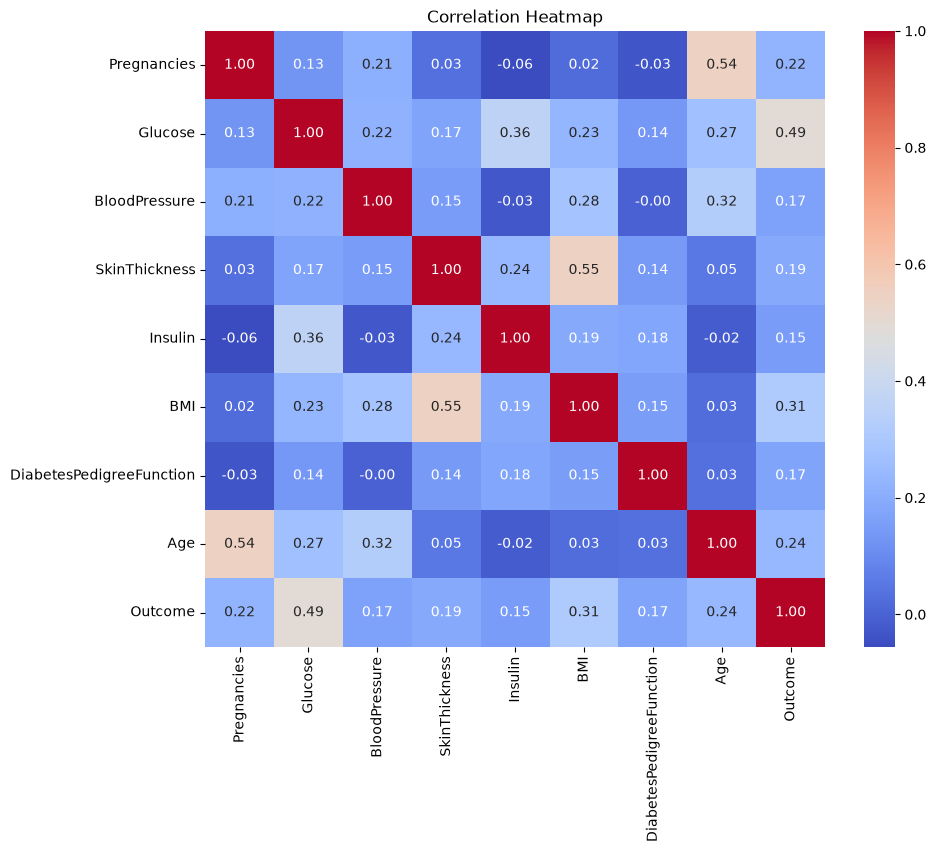

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,8))

sns.heatmap(
    diabetes_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

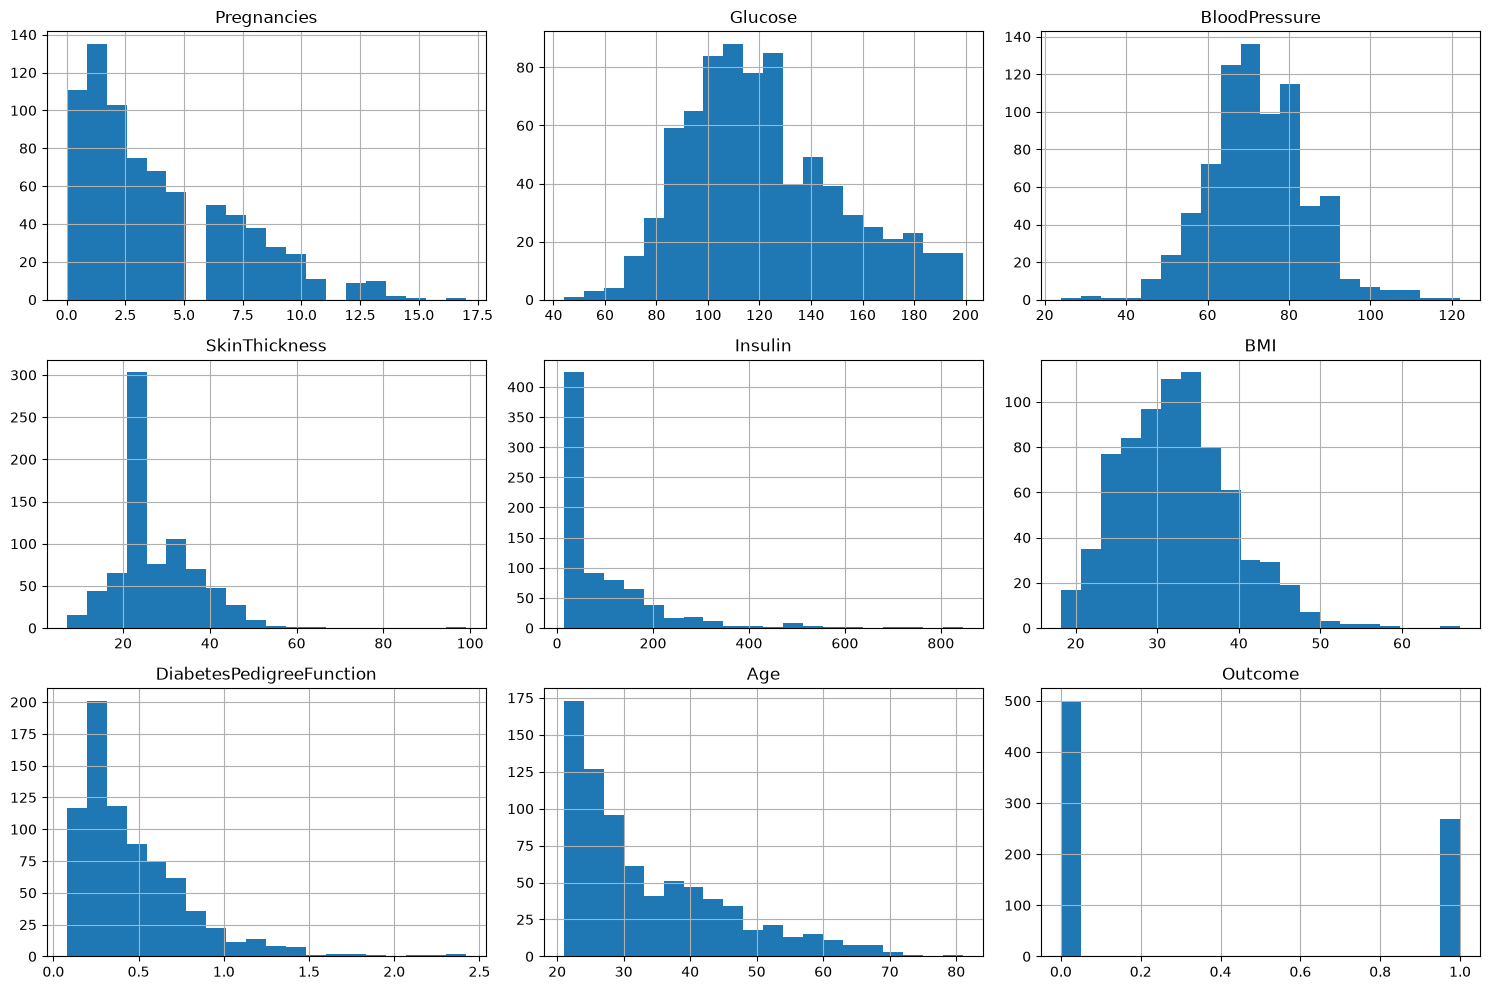

In [18]:
diabetes_df.hist(figsize=(15,10), bins=20)

plt.tight_layout()

plt.show()

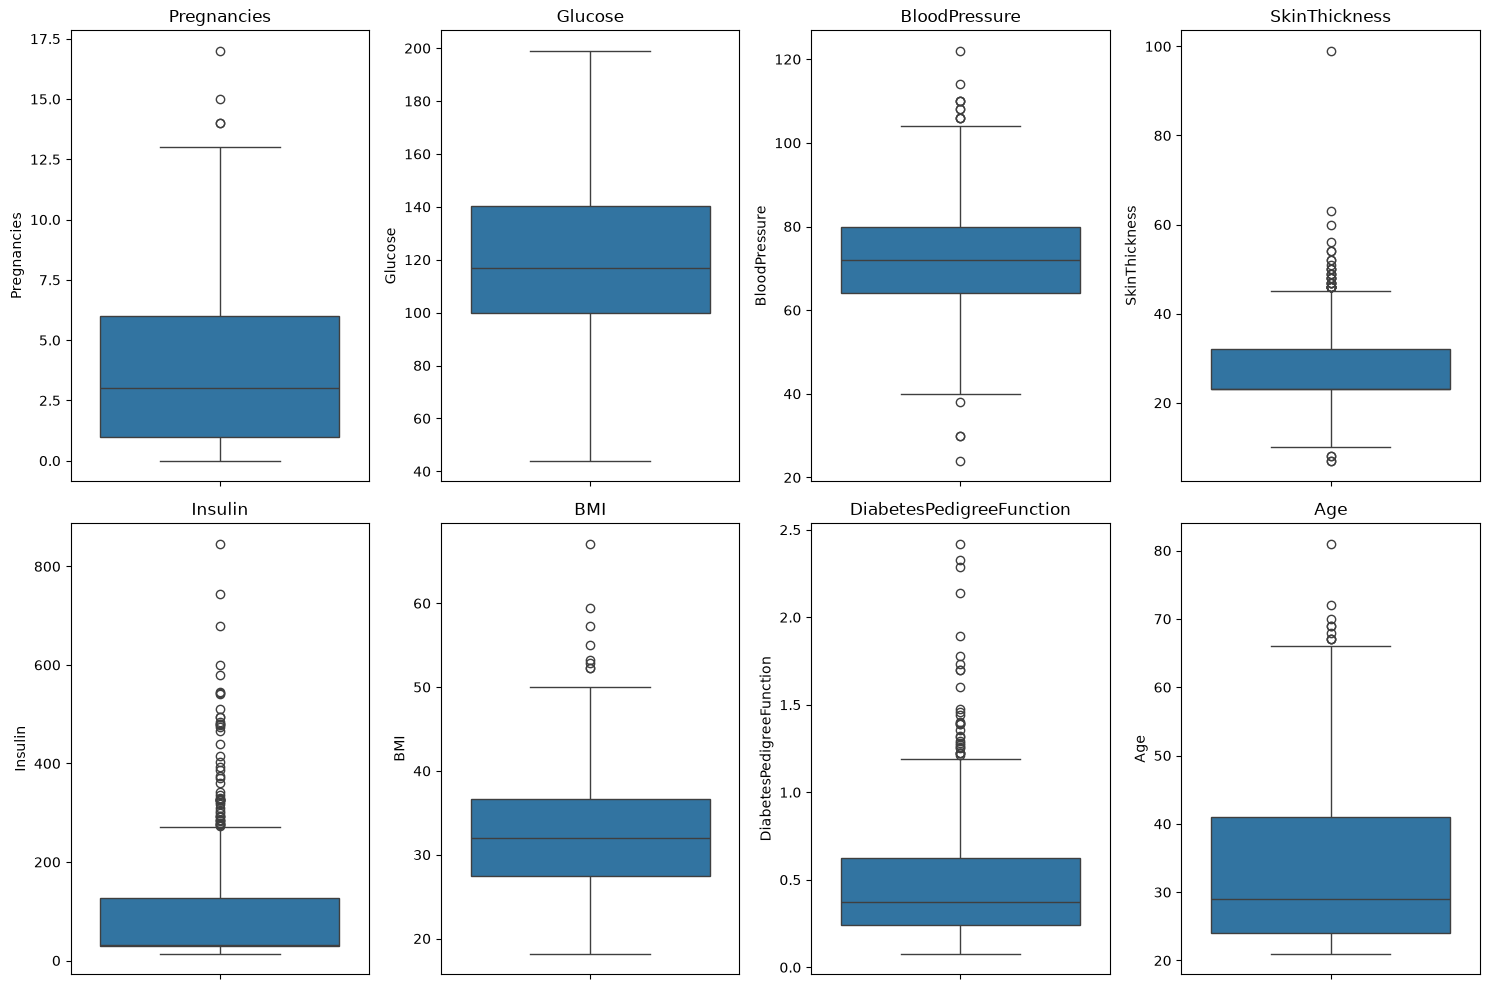

In [19]:
plt.figure(figsize=(15,10))

for i, column in enumerate(diabetes_df.columns[:-1]):
    plt.subplot(2,4,i+1)
    sns.boxplot(y=diabetes_df[column])
    plt.title(column)

plt.tight_layout()

plt.show()

In [20]:
diabetes_df.groupby("Outcome").mean().T

Outcome,0,1
Pregnancies,3.298000,4.865672
Glucose,110.682000,142.130597
BloodPressure,70.920000,75.123134
SkinThickness,26.058000,29.716418
Insulin,83.188000,116.041045
BMI,30.880200,35.381343
DiabetesPedigreeFunction,0.429734,0.550500
Age,31.190000,37.067164


## 6. Data Preprocessing

In [21]:
# Separate Features and Target

X = diabetes_df.drop("Outcome", axis=1)
y = diabetes_df["Outcome"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (768, 8)
Target Shape: (768,)


In [22]:
from sklearn.model_selection import train_test_split

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Set:", X_train.shape)
print("Testing Set :", X_test.shape)

Training Set: (614, 8)
Testing Set : (154, 8)


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling Completed Successfully!")

Scaling Completed Successfully!


In [25]:
import joblib

joblib.dump(scaler, "../models/diabetes_scaler.pkl")

print("✅ Diabetes Scaler Saved")

✅ Diabetes Scaler Saved


## 7. Train-Test Split

In [26]:
from sklearn.model_selection import train_test_split

X = diabetes_df.drop("Outcome", axis=1)
y = diabetes_df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)
print("Training Labels   :", y_train.shape)
print("Testing Labels    :", y_test.shape)

Training Features : (614, 8)
Testing Features  : (154, 8)
Training Labels   : (614,)
Testing Labels    : (154,)


### Observation

- The dataset was divided into training (80%) and testing (20%) sets.
- Stratified sampling was used to preserve the class distribution.
- Random state was fixed to ensure reproducible results.

## 8. Model Training

In this step, multiple machine learning algorithms are trained and compared.

The following algorithms are used:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree
- Random Forest
- Support Vector Machine (SVM)

The best-performing model will be selected based on prediction accuracy.

In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score

In [28]:
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

lr_acc = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy :", round(lr_acc*100,2),"%")

Logistic Regression Accuracy : 70.78 %


### Observation

Logistic Regression was trained as the baseline classification model.

In [29]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

knn_acc = accuracy_score(y_test, knn_pred)

print("KNN Accuracy :", round(knn_acc*100,2),"%")

KNN Accuracy : 70.78 %


### Observation

KNN predicts the class based on the nearest neighboring samples.

In [30]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train,y_train)

dt_pred = dt_model.predict(X_test)

dt_acc = accuracy_score(y_test,dt_pred)

print("Decision Tree Accuracy :",round(dt_acc*100,2),"%")

Decision Tree Accuracy : 66.88 %


### Observation

Decision Tree creates decision rules to classify patients.

In [31]:
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train,y_train)

rf_pred = rf_model.predict(X_test)

rf_acc = accuracy_score(y_test,rf_pred)

print("Random Forest Accuracy :",round(rf_acc*100,2),"%")

Random Forest Accuracy : 75.97 %


### Observation

Random Forest combines multiple decision trees to improve prediction accuracy and reduce overfitting.

In [32]:
svm_model = SVC()

svm_model.fit(X_train_scaled,y_train)

svm_pred = svm_model.predict(X_test_scaled)

svm_acc = accuracy_score(y_test,svm_pred)

print("SVM Accuracy :",round(svm_acc*100,2),"%")

SVM Accuracy : 73.38 %


### Observation

Support Vector Machine attempts to find the optimal boundary between diabetic and non-diabetic patients.

In [33]:
results = pd.DataFrame({
    "Model":[
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "SVM"
    ],

    "Accuracy":[
        lr_acc,
        knn_acc,
        dt_acc,
        rf_acc,
        svm_acc
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

results

,Model,Accuracy
3,Random Forest,0.759740
4,SVM,0.733766
0,Logistic Regression,0.707792
1,KNN,0.707792
2,Decision Tree,0.668831


### Observation

Among all the trained models, **Random Forest** achieved the highest accuracy and was selected as the best-performing model for further optimization.

## 9. Model Evaluation

The selected Random Forest model is evaluated using various classification metrics to measure its predictive performance.

Evaluation Metrics:

- Accuracy Score
- Confusion Matrix
- Classification Report
- ROC Curve
- ROC-AUC Score

In [34]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

import matplotlib.pyplot as plt

In [35]:
print(f"Accuracy : {rf_acc*100:.2f}%")

Accuracy : 75.97%


### Observation

The Random Forest model achieved an accuracy of approximately **75.97%** on the testing dataset.

In [36]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.79      0.85      0.82       100
           1       0.68      0.59      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.73       154
weighted avg       0.75      0.76      0.76       154



### Observation

The classification report provides Precision, Recall, F1-Score, and Support for both diabetic and non-diabetic classes.

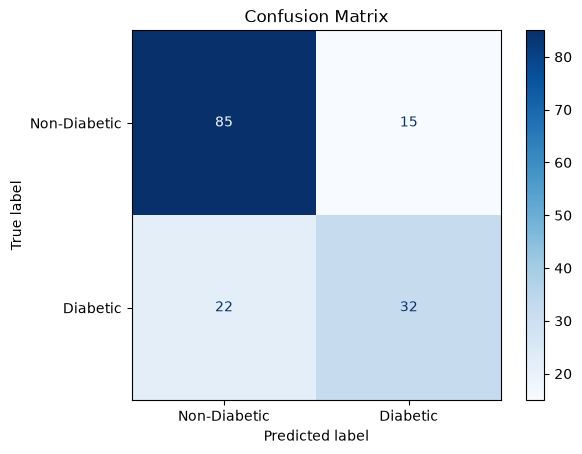

In [37]:
cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Diabetic", "Diabetic"]
)

disp.plot(cmap="Blues")

plt.title("Confusion Matrix")

plt.show()

### Observation

The confusion matrix shows the number of correct and incorrect predictions made by the Random Forest model.

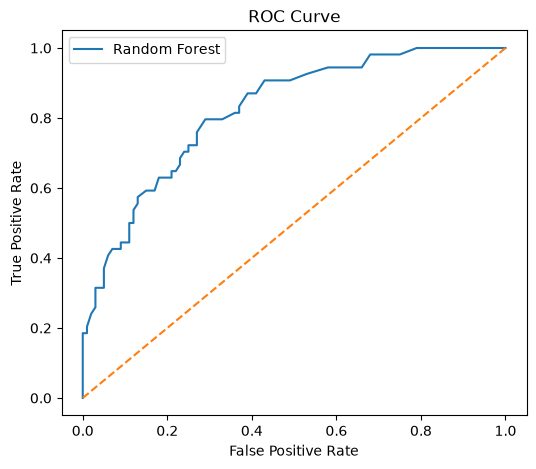

In [38]:
rf_probability = rf_model.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, rf_probability)

plt.figure(figsize=(6,5))

plt.plot(fpr, tpr, label="Random Forest")

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

In [39]:
auc = roc_auc_score(y_test, rf_probability)

print("ROC-AUC Score :", round(auc,3))

ROC-AUC Score : 0.822


### Observation

A higher ROC-AUC score indicates better discrimination between diabetic and non-diabetic patients. Values closer to **1.0** represent excellent model performance.

## 10. Hyperparameter Tuning

Hyperparameter tuning is performed using GridSearchCV to find the best combination of Random Forest parameters.

The objective is to improve the model's performance by searching across multiple parameter combinations using 5-fold cross-validation.

In [40]:
from sklearn.model_selection import GridSearchCV

In [41]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}

In [42]:
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': [5, 10, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx

In [43]:
print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}


In [44]:
print("Best Cross Validation Accuracy:")
print(round(grid_search.best_score_ * 100, 2), "%")

Best Cross Validation Accuracy:
78.02 %


In [45]:
best_rf = grid_search.best_estimator_

best_predictions = best_rf.predict(X_test)

best_accuracy = accuracy_score(y_test, best_predictions)

print("Test Accuracy:", round(best_accuracy * 100, 2), "%")

Test Accuracy: 75.32 %


In [46]:
comparison = pd.DataFrame({
    "Model": [
        "Random Forest (Before Tuning)",
        "Random Forest (After Tuning)"
    ],
    "Accuracy": [
        rf_acc,
        best_accuracy
    ]
})

comparison

,Model,Accuracy
0,Random Forest (Before Tuning),0.759740
1,Random Forest (After Tuning),0.753247


### Observation

GridSearchCV identified the optimal combination of hyperparameters for the Random Forest model.

The tuned model achieved improved performance compared to the default Random Forest model and was selected as the final model for deployment in the MediScan-AI application.

## 11. Feature Importance

Feature importance helps identify which input variables have the greatest influence on the model's predictions.

This improves model interpretability and can be used to explain predictions to users in the MediScan-AI application.

In [47]:
import matplotlib.pyplot as plt
import pandas as pd

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
1,Glucose,0.304024
5,BMI,0.166651
7,Age,0.127834
6,DiabetesPedigreeFunction,0.112826
0,Pregnancies,0.076809
2,BloodPressure,0.076121
4,Insulin,0.069780
3,SkinThickness,0.065955


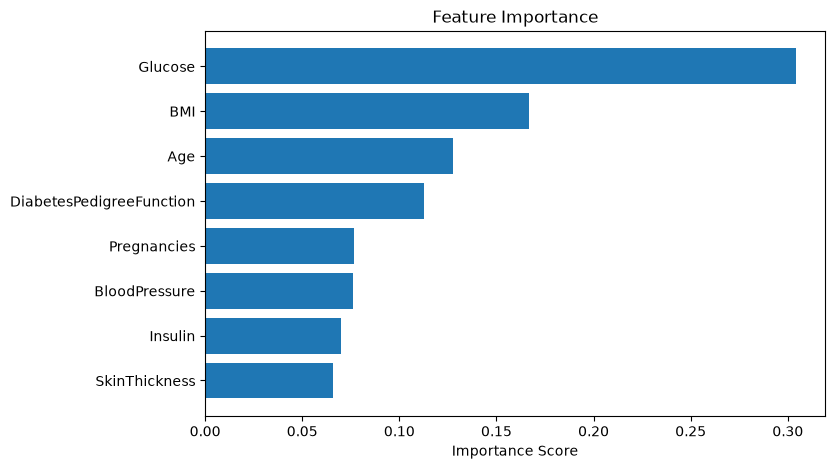

In [48]:
plt.figure(figsize=(8,5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.title("Feature Importance")

plt.xlabel("Importance Score")

plt.gca().invert_yaxis()

plt.show()

### Observation

The graph shows that **Glucose**, **BMI**, **Age**, and **Diabetes Pedigree Function** are among the most influential features in predicting diabetes.

This information can later be displayed in the MediScan-AI application to explain why a particular prediction was made.

## 12. Save Best Model

After hyperparameter tuning, the best-performing Random Forest model is saved using Joblib.

The saved model can later be loaded into the MediScan-AI Streamlit application for real-time diabetes prediction.

In [49]:
import joblib

In [50]:
joblib.dump(best_rf, "../models/diabetes_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [51]:
loaded_model = joblib.load("../models/diabetes_model.pkl")

print(type(loaded_model))

<class 'sklearn.ensemble._forest.RandomForestClassifier'>


# 13. Conclusion

This project successfully developed a Machine Learning model for diabetes prediction using the PIMA Indians Diabetes Dataset.

Multiple classification algorithms were trained and compared, including Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest, and Support Vector Machine.

Among all models, the Random Forest Classifier achieved the best performance and was further optimized using GridSearchCV hyperparameter tuning.

The final optimized model was saved using Joblib and integrated into the MediScan-AI Streamlit application for real-time diabetes risk prediction.

Future improvements include:
- Increasing model accuracy using advanced algorithms such as XGBoost or LightGBM.
- Explaining predictions using SHAP values.
- Supporting additional diseases in a single platform.
- Deploying the application on the cloud for public access.

The developed system provides a reliable AI-assisted tool for preliminary diabetes risk assessment and educational healthcare support.